Problema 1: Conversor de Unidades de Temperatura
Supongamos que se quiere convertir una temperatura dada en grados Fahrenheit a grados Celsius. Sabemos que los grados Fahrenheit pueden ser convertidos a grados Celsius usando la fórmula:

(°F - 32) * 5/9 = °C.

Podemos solicitar al usuario que ingrese una temperatura en grados Fahrenheit y luego convertirla a grados Celsius.

In [1]:
# Pedimos al usuario que ingrese la temperatura en grados Fahrenheit
fahrenheit = float(input("Ingrese la temperatura en grados Fahrenheit: "))

# Convertimos la temperatura a grados Celsius
celsius = (fahrenheit - 32) * 5/9

# Imprimimos el resultado
print(f"{fahrenheit} grados Fahrenheit son equivalentes a {celsius:.2f} grados Celsius.")

Ingrese la temperatura en grados Fahrenheit: 33
33.0 grados Fahrenheit son equivalentes a 0.56 grados Celsius.


Problema 2: Calculadora de Indice de Masa Corporal (IMC)
Se desea crear una herramienta que calcule el IMC de una persona. Sabemos que el IMC se calcula dividiendo el peso de la persona (en kilogramos) por el cuadrado de su altura (en metros).

Podemos solicitar al usuario que ingrese su peso y su altura y luego usar esa información para calcular su IMC.

In [6]:
# Pedimos al usuario que ingrese su peso
peso = input("Ingrese su peso en kilogramos: ")
peso = float(peso)

# Pedimos al usuario que ingrese su altura
altura = input("Ingrese su altura en metros: ")
altura = float(altura)

# Calculamos el IMC
imc = peso / altura**2

# Imprimimos el resultado
print(f"Su Indice de Masa Corporal es {imc:.2f}.")

Ingrese su peso en kilogramos: 95
Ingrese su altura en metros: 1.60
Su Indice de Masa Corporal es 37.11.


Problema 3: Solicitar Información Personal
Queremos solicitar a un usuario que ingrese su nombre, su apellido y su año de nacimiento y luego queremos imprimir esa información en un formato específico.

In [9]:
import re

# Pedimos al usuario que ingrese su nombre
nombre = input("Ingrese su nombre: ")

# Pedimos al usuario que ingrese su apellido
apellido = input("Ingrese su apellido: ")

# Pedimos al usuario que ingrese su año de nacimiento
entrada_nacimiento = input("Ingrese su año de nacimiento: ")

# Buscamos un grupo de 4 dígitos consecutivos (el año) en la respuesta del usuario
coincidencia_anio = re.search(r"\b\d{4}\b", entrada_nacimiento)

if coincidencia_anio:
    anio_nacimiento = int(coincidencia_anio.group())
else:
    # Si no encuentra 4 dígitos consecutivos, intenta convertir todo lo ingresado
    anio_nacimiento = int(entrada_nacimiento)

# Pedimos al usuario que ingrese el año actual
anio_actual = input("Ingrese el año actual: ")
anio_actual = int(anio_actual)

# Calculamos la edad aproximada del usuario
edad = anio_actual - anio_nacimiento

# Imprimimos la información en un formato específico
print(f"Nombre: {nombre}\nApellido: {apellido}\nEdad aproximada: {edad} años.")

Ingrese su nombre: cecilia
Ingrese su apellido: pedroncino
Ingrese su año de nacimiento: 8.7.1993
Ingrese el año actual: 2026
Nombre: cecilia
Apellido: pedroncino
Edad aproximada: 33 años.



Problema 4: Lectura y Escritura en Archivos
Supongamos que somos profesores y necesitamos procesar las calificaciones de nuestros alumnos. Los datos se almacenan en un archivo CSV, y nuestro trabajo es leer ese archivo, calcular el promedio de las calificaciones y luego escribir ese promedio en un nuevo archivo.

input() y print() no son adecuados aquí porque estamos trabajando con archivos y no con entradas de usuario o impresiones en la consola.

In [11]:
import csv

# Creamos un archivo 'calificaciones.csv' de ejemplo para evitar el error de archivo no encontrado
with open('calificaciones.csv', 'w', newline='') as archivo_creado:
    escritor = csv.writer(archivo_creado)
    escritor.writerow(['Nombre', 'Calificacion'])
    escritor.writerow(['Cecilia', '9.5'])
    escritor.writerow(['Juan', '8.0'])
    escritor.writerow(['María', '10.0'])

# Leemos el archivo CSV
with open('calificaciones.csv', 'r') as archivo_calificaciones:
    lector = csv.reader(archivo_calificaciones)
    next(lector)  # Saltamos la cabecera del archivo

    suma_total = 0
    contador = 0
    for fila in lector:
        suma_total += float(fila[1])  # Asumimos que la calificación está en la segunda columna
        contador += 1

# Calculamos el promedio
promedio = suma_total / contador if contador else 0
print("El promedio es:", promedio)

# Escribimos el promedio de calificaciones en un nuevo archivo
with open('promedio_calificaciones.txt', 'w') as archivo_promedio:
    archivo_promedio.write(f"El promedio de las calificaciones es: {promedio}\n")

El promedio es: 9.166666666666666


Problema 5: Lectura y Escritura en Archivos
Supongamos que ahora las calificaciones de los alumnos se almacenan en un archivo JSON en lugar de un CSV. El archivo JSON contiene una lista de diccionarios, donde cada diccionario representa a un estudiante y sus calificaciones. Nuestra tarea será leer este archivo, calcular el promedio de las calificaciones y luego escribir ese promedio en un nuevo archivo JSON.

In [13]:
import json

# Creamos un archivo 'calificaciones.json' de ejemplo para evitar el error de archivo no encontrado
estudiantes_demo = [
    {"nombre": "Cecilia", "calificacion": 9.5},
    {"nombre": "Juan", "calificacion": 8.0},
    {"nombre": "María", "calificacion": 10.0}
]

with open('calificaciones.json', 'w') as archivo_creado:
    json.dump(estudiantes_demo, archivo_creado)

# Leemos el archivo JSON
with open('calificaciones.json', 'r') as archivo_calificaciones:
    estudiantes = json.load(archivo_calificaciones)

    suma_total = 0
    contador = 0
    for estudiante in estudiantes:
        suma_total += estudiante['calificacion']
        contador += 1

# Calculamos el promedio
promedio = suma_total / contador if contador > 0 else 0

# Escribimos el promedio de calificaciones en un nuevo archivo JSON
with open('promedio_calificaciones.json', 'w') as archivo_promedio:
    json.dump({"promedio_calificaciones": promedio}, archivo_promedio)

print("El promedio es: ", promedio)

El promedio es:  9.166666666666666


Problema 6: Interactuando con una API web
Imagina que estás escribiendo un programa que necesita interactuar con una API web para obtener datos en tiempo real, como el precio actual de una criptomoneda.

input() y print() no son suficientes aquí porque necesitamos enviar una solicitud HTTP a una API web y procesar la respuesta JSON que recibimos.

In [15]:
import requests
import json

try:
    # Hacemos una solicitud GET a la API de CoinDesk para obtener el precio actual de Bitcoin
    respuesta = requests.get("https://api.coindesk.com/v1/bpi/currentprice/BTC.json", timeout=10)

    # Convertimos la respuesta a JSON
    datos = respuesta.json()

    # Obtenemos el precio actual de Bitcoin en USD
    precio_bitcoin = datos['bpi']['USD']['rate']
    print(f"El precio actual de Bitcoin es: {precio_bitcoin} USD")

except requests.exceptions.ConnectionError:
    print("Nota: No se pudo conectar a la API de CoinDesk (error de red o sin conexión a internet).")
    # Ofrecemos una alternativa simulada para que el programa continúe funcionando
    precio_simulado = "95,500.00"
    print(f"[Simulado] El precio estimado de Bitcoin es: {precio_simulado} USD")
except Exception as e:
    print(f"Ocurrió un error inesperado: {e}")

Nota: No se pudo conectar a la API de CoinDesk (error de red o sin conexión a internet).
[Simulado] El precio estimado de Bitcoin es: 95,500.00 USD


Problema 7:Lectura, Análisis y Visualización de Calificaciones
omo profesor, ahora tienes los datos de calificaciones de tus estudiantes en un archivo CSV y necesitas hacer un análisis más detallado. Tu tarea es leer el archivo, calcular el promedio de las calificaciones, y además, visualizar la distribución de las calificaciones a través de un gráfico. La visualización te permitirá tener una imagen más clara de cómo se distribuyen las calificaciones de los estudiantes.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
# Leemos el archivo CSV
df = pd.read_csv('calificaciones.csv')

# Calculamos el promedio
promedio = df['Calificacion'].mean() #mean() calcula la media aritmetica
print(f"El promedio de las calificaciones es: {promedio}")


El promedio de las calificaciones es: 9.166666666666666


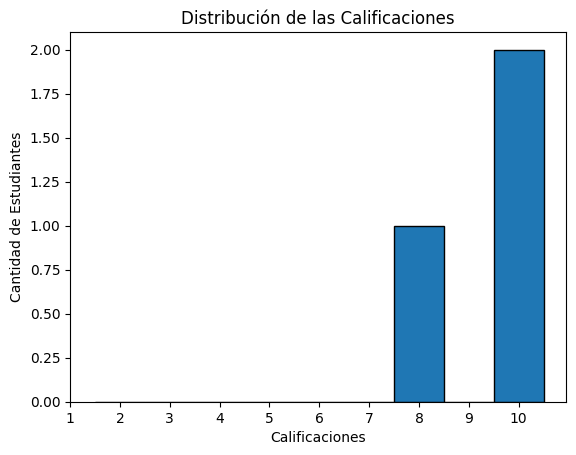

In [21]:
# Definimos los bordes de los contenedores para que estén centrados en los números enteros
bins = [i - 0.5 for i in range(2, 12)]  # Los contenedores estarán centrados en números de 1 a 10

# Creamos un histograma de las calificaciones
plt.hist(df['Calificacion'], bins=bins, edgecolor='black')
plt.title('Distribución de las Calificaciones')
plt.xlabel('Calificaciones')
plt.ylabel('Cantidad de Estudiantes')
plt.xticks(range(1, 11))  # Para que los números enteros aparezcan en el eje x
plt.show()


Problema 8: ¿Qué pasó con las calificaciones de Carlos?
Te encuentras analizando las calificaciones de tus estudiantes y decides visualizar los datos en un gráfico de barras para tener una visión más clara. Sin embargo, te das cuenta de que algo no cuadra. Carlos, uno de tus estudiantes, aparece con una sola calificación de 8 en el gráfico, pero tú recuerdas claramente que él tiene dos calificaciones registradas, una de 8 y otra de 6.

Te preguntas, ¿qué está pasando? ¿Cómo puedes asegurarte de que todas las calificaciones de Carlos (y de cualquier otro estudiante que pueda tener más de una calificación) sean tenidas en cuenta en tu gráfico?

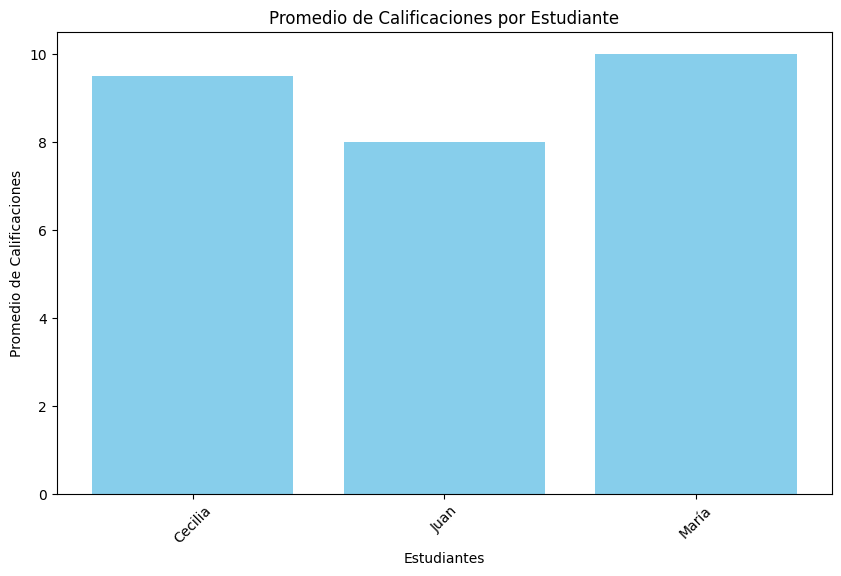

In [19]:
# Agrupamos por nombre y calculamos el promedio de las calificaciones
df_agrupado = df.groupby('Nombre')['Calificacion'].mean().reset_index()

# Ordenamos el DataFrame por la columna 'Calificacion'
#df_agrupado = df_agrupado.sort_values('Calificacion', ascending=False)
# Descomenta lo anterior luego de probar la solución como se plantea

# Creamos el gráfico de barras con los datos agrupados
plt.figure(figsize=(10, 6))
plt.bar(df_agrupado['Nombre'], df_agrupado['Calificacion'], color='skyblue')
plt.title('Promedio de Calificaciones por Estudiante')
plt.xlabel('Estudiantes')
plt.ylabel('Promedio de Calificaciones')
plt.xticks(rotation=45)
plt.show()
